# 03 · Predicting large spread increases

**Nhi Dinh**

Can first-half liquidity conditions help identify windows where the spread will widen sharply?

We define a widening event, compare thresholds, explore differences between stocks and fit a grouped logistic-regression baseline. The event occurs when the second-half snapshot 90th-percentile spread is at least 1.5 times the first-half snapshot median.

This is a separate question from forecasting average spread changes. This version includes the code but has no saved performance results; it has not been rerun on the full dataset.

[All notebooks](RESEARCH_GUIDE.md).


In [1]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Erdos-Projects/fall-2026-short-horizon-forecasting"
DATA_DIR = os.environ.get("OBF_DATA_DIR", "")      # e.g. "/path/to/optiver-realized-volatility-prediction"
CONFIG = "configs/default.yaml"                     # "configs/smoke.yaml" for a quick 3-stock test

if IN_COLAB:
    if not Path("fall-2026-short-horizon-forecasting").exists():
        !git clone -q {REPO_URL}
    %cd fall-2026-short-horizon-forecasting
    %pip install -q -r requirements.txt
    %pip install -q -e .
    if not DATA_DIR:
        from google.colab import userdata
        import kagglehub
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        DATA_DIR = "/content/data/optiver-realized-volatility-prediction"
        kagglehub.competition_download("optiver-realized-volatility-prediction", output_dir=DATA_DIR)
else:
    root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(root)
    sys.path.insert(0, str(root / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from obforecast.config import load_config
from obforecast.data import ParquetSource, check_layout, resolve_data_dir

cfg = load_config(CONFIG)
data_dir = resolve_data_dir(DATA_DIR or None, cfg)
layout = check_layout(data_dir)
source = ParquetSource(data_dir)
DATA_DIR = data_dir
train = pd.read_csv(data_dir / "train.csv")
STOCK_ID = int(sorted(train.stock_id.unique())[0])
def load_stock(kind, stock_id):
    return source.load(kind, int(stock_id)).sort_values(
        ["time_id", "seconds_in_bucket"]).reset_index(drop=True)
book = load_stock("book", STOCK_ID)
trades = load_stock("trade", STOCK_ID)
print(f"{train.stock_id.nunique()} stocks; sample stock {STOCK_ID}")


112 stocks; sample stock 0


## Bid–ask spread widening events

**Question.** Using only order-book observations from seconds 0–299, can we predict whether the spread will widen during seconds 300–599?

For each stock and 10-minute window, define `spread_bps = (ask_price1 - bid_price1) / midpoint × 10,000`. The continuous outcome is the 90th-percentile spread in the second half divided by the median spread in the first half. The binary event is 1 when this ratio is at least **1.5×**. Using a percentile in the outcome makes the label less sensitive to a single noisy quote; the fixed 1.5× threshold is interpretable and the sensitivity table below shows how class balance changes at nearby thresholds. All predictors are computed strictly before second 300 to prevent leakage.

The validation split holds out entire `time_id` groups so that observations from the same market window cannot appear in both train and test. (`time_id` values are identifiers, not a guaranteed chronological sequence.)

In [3]:
# Build one leakage-safe row per (stock_id, time_id). This may take a few minutes.
from time import perf_counter

EVENT_RATIO = 1.50

def add_book_features(df):
    df = df.copy()
    df["mid_price"] = (df["bid_price1"] + df["ask_price1"]) / 2
    df["spread_bps"] = (df["ask_price1"] - df["bid_price1"]) / df["mid_price"] * 10_000
    df["depth"] = df[["bid_size1", "ask_size1", "bid_size2", "ask_size2"]].sum(axis=1)
    df["imbalance"] = (df["bid_size1"] - df["ask_size1"]) / (df["bid_size1"] + df["ask_size1"]).replace(0, np.nan)
    df["wap1"] = (df["bid_price1"] * df["ask_size1"] + df["ask_price1"] * df["bid_size1"]) / (df["bid_size1"] + df["ask_size1"]).replace(0, np.nan)
    return df

def summarize_window(group):
    first = group[group["seconds_in_bucket"] < 300].sort_values("seconds_in_bucket")
    second = group[group["seconds_in_bucket"] >= 300]
    if first.empty or second.empty:
        return None
    x = first["seconds_in_bucket"].to_numpy()
    spread = first["spread_bps"].to_numpy()
    slope = np.polyfit(x, spread, 1)[0] if len(first) > 1 and np.ptp(x) > 0 else 0.0
    log_wap = np.log(first["wap1"]).replace([np.inf, -np.inf], np.nan).dropna()
    fh_median = first["spread_bps"].median()
    sh_q90 = second["spread_bps"].quantile(0.90)
    return pd.Series({
        "first_spread_median": fh_median,
        "first_spread_mean": first["spread_bps"].mean(),
        "first_spread_std": first["spread_bps"].std(),
        "first_spread_q90": first["spread_bps"].quantile(0.90),
        "first_spread_max": first["spread_bps"].max(),
        "first_spread_last": first["spread_bps"].iloc[-1],
        "first_spread_slope": slope,
        "first_depth_median": first["depth"].median(),
        "first_depth_q10": first["depth"].quantile(0.10),
        "first_imbalance_mean": first["imbalance"].mean(),
        "first_imbalance_std": first["imbalance"].std(),
        "first_imbalance_last": first["imbalance"].iloc[-1],
        "first_wap_realized_vol": np.sqrt(np.square(log_wap.diff().dropna()).sum()),
        "first_quote_count": len(first),
        "first_seconds_covered": first["seconds_in_bucket"].nunique(),
        "second_spread_q90": sh_q90,
        "widening_ratio": sh_q90 / fh_median if fh_median > 0 else np.nan,
    })

started = perf_counter()
window_rows = []
for stock_id in sorted(train["stock_id"].unique()):
    stock_book = add_book_features(load_stock("book", int(stock_id)))
    stock_summary = stock_book.groupby("time_id", sort=False).apply(summarize_window).dropna(how="all").reset_index()
    stock_summary.insert(0, "stock_id", int(stock_id))
    window_rows.append(stock_summary)

spread_events = pd.concat(window_rows, ignore_index=True)
spread_events = spread_events.replace([np.inf, -np.inf], np.nan).dropna(subset=["widening_ratio"])
spread_events["spread_widening_event"] = (spread_events["widening_ratio"] >= EVENT_RATIO).astype(int)
print(f"Built {len(spread_events):,} windows in {(perf_counter() - started) / 60:.1f} minutes")
display(spread_events.head())

Built 428,932 windows in 45.9 minutes


,stock_id,time_id,first_spread_median,first_spread_mean,first_spread_std,first_spread_q90,first_spread_max,first_spread_last,first_spread_slope,first_depth_median,first_depth_q10,first_imbalance_mean,first_imbalance_std,first_imbalance_last,first_wap_realized_vol,first_quote_count,first_seconds_covered,second_spread_q90,widening_ratio,spread_widening_event
0,0,5,8.759069,8.771946,1.836374,11.845572,13.933441,11.845695,0.005725,333.0,192.4,-0.007605,0.695452,-0.948052,0.003394,163.0,163.0,10.931599,1.248032,0
1,0,11,4.015867,4.499651,1.822242,7.028026,9.034956,2.006930,-0.018134,339.0,151.8,0.037370,0.792217,-0.666667,0.000699,85.0,85.0,5.016068,1.249062,0
2,0,16,7.179884,7.455355,1.614618,9.571957,11.491225,9.095509,-0.008809,392.0,208.0,0.103075,0.532542,0.526316,0.001983,120.0,120.0,9.578650,1.334095,0
3,0,31,7.877407,8.819750,2.819636,12.508418,14.360341,6.487742,0.014415,429.0,251.6,0.079501,0.653986,0.886792,0.001863,67.0,67.0,11.403942,1.447677,0
4,0,62,3.730071,3.687470,1.125955,5.129822,7.460689,6.062233,-0.002758,293.0,125.0,0.319399,0.675108,-0.335505,0.001131,87.0,87.0,6.528407,1.750210,1


## Threshold sensitivity and cross-stock variation

The fixed 1.5× event is evaluated alongside nearby thresholds. Inspect prevalence before interpreting accuracy; average precision should be compared with the test event rate.

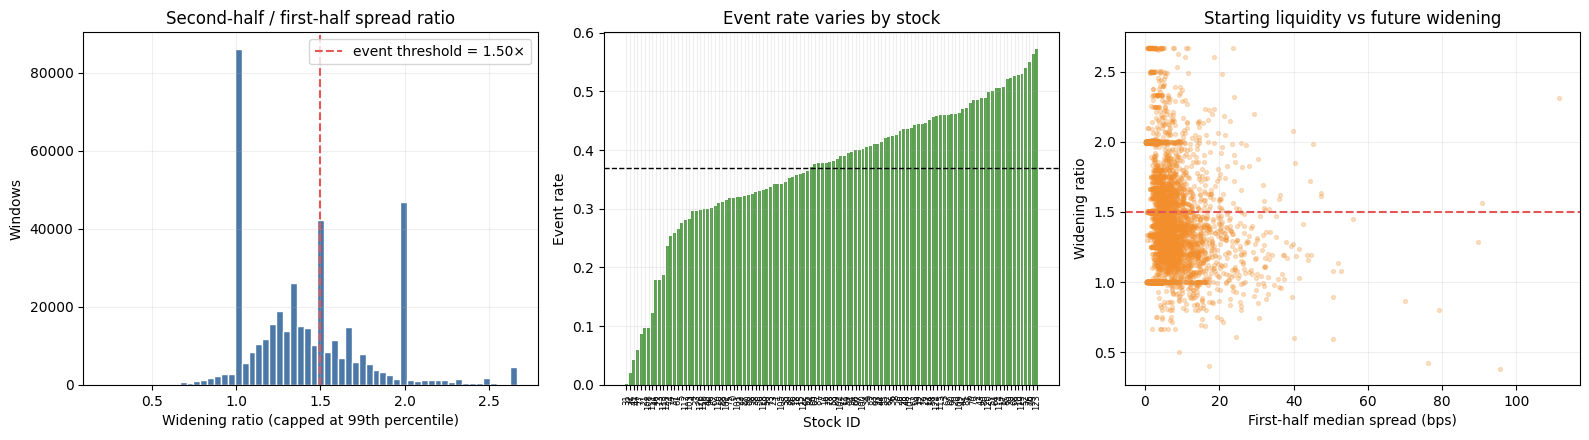

Chosen event prevalence: 36.9%


,widening_ratio_threshold,event_prevalence
0,1.250000,63.2%
1,1.500000,36.9%
2,1.750000,19.7%
3,2.000000,8.5%


,count,mean,std,min,25%,50%,75%,max
event_rate,112.0,0.368927,0.119522,0.001567,0.317556,0.38094,0.456462,0.572063
windows,112.0,3829.750000,1.700556,3815.000000,3830.000000,3830.00000,3830.000000,3830.000000


In [4]:
# EDA: class balance, threshold sensitivity, and cross-stock heterogeneity.
thresholds = [1.25, 1.50, 1.75, 2.00]
sensitivity = pd.DataFrame({
    "widening_ratio_threshold": thresholds,
    "event_prevalence": [(spread_events["widening_ratio"] >= t).mean() for t in thresholds],
})
by_stock = (spread_events.groupby("stock_id")["spread_widening_event"]
            .agg(["mean", "size"]).rename(columns={"mean": "event_rate", "size": "windows"})
            .sort_values("event_rate"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ratio_cap = spread_events["widening_ratio"].quantile(0.99)
axes[0].hist(spread_events["widening_ratio"].clip(upper=ratio_cap), bins=60, color="#4C78A8", edgecolor="white")
axes[0].axvline(EVENT_RATIO, color="#E45756", linestyle="--", label=f"event threshold = {EVENT_RATIO:.2f}×")
axes[0].set(title="Second-half / first-half spread ratio", xlabel="Widening ratio (capped at 99th percentile)", ylabel="Windows")
axes[0].legend()
axes[1].bar(by_stock.index.astype(str), by_stock["event_rate"], color="#59A14F")
axes[1].axhline(spread_events["spread_widening_event"].mean(), color="black", linestyle="--", linewidth=1)
axes[1].set(title="Event rate varies by stock", xlabel="Stock ID", ylabel="Event rate")
axes[1].tick_params(axis="x", labelrotation=90, labelsize=6)
sample_points = spread_events.sample(min(5000, len(spread_events)), random_state=42)
axes[2].scatter(sample_points["first_spread_median"], sample_points["widening_ratio"].clip(upper=ratio_cap), s=8, alpha=0.25, color="#F28E2B")
axes[2].axhline(EVENT_RATIO, color="#E45756", linestyle="--")
axes[2].set(title="Starting liquidity vs future widening", xlabel="First-half median spread (bps)", ylabel="Widening ratio")
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Chosen event prevalence: {spread_events['spread_widening_event'].mean():.1%}")
display(sensitivity.style.format({"event_prevalence": "{:.1%}"}))
display(by_stock.describe().T)

## Grouped baseline and interpretation

All rows from a `time_id` stay together. Imputation, scaling and stock encoding are fitted in the training pipeline. The 0.5 classification threshold is fixed. `class_weight="balanced"` changes the fitting objective; the output scores are not automatically calibrated probabilities.

Train windows: 343,146; test windows: 85,786
Train prevalence: 36.8%; test prevalence: 37.2%
ROC AUC: 0.787
Average precision: 0.663 (no-skill baseline = 0.372)


              precision    recall  f1-score   support

           0      0.830     0.646     0.727     53892
           1      0.565     0.777     0.654     31894

    accuracy                          0.695     85786
   macro avg      0.698     0.712     0.691     85786
weighted avg      0.732     0.695     0.700     85786



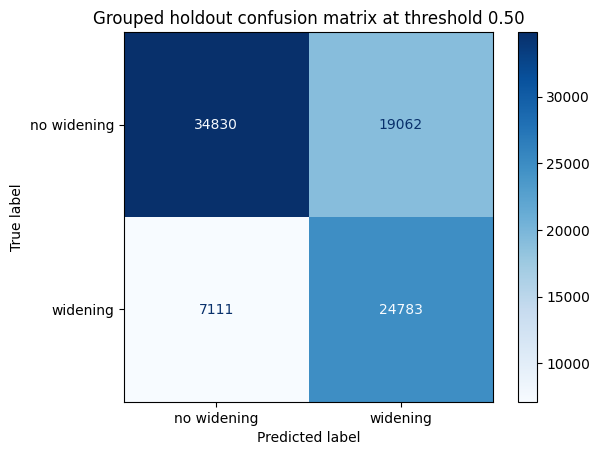

,logistic_coefficient
numeric__first_spread_median,-8.330415
numeric__first_depth_q10,-6.588192
stock__stock_id_41,-1.302105
stock__stock_id_47,-1.301669
stock__stock_id_21,-1.190747
stock__stock_id_113,-1.119165
stock__stock_id_61,-0.994981
stock__stock_id_111,-0.951444
stock__stock_id_13,-0.728923
stock__stock_id_50,-0.700580


In [5]:
# Grouped baseline: hold out complete time_id groups and score the rare-event ranking.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

target_col = "spread_widening_event"
leakage_cols = {target_col, "second_spread_q90", "widening_ratio", "time_id"}
feature_cols = [c for c in spread_events.columns if c not in leakage_cols]
X = spread_events[feature_cols]
y = spread_events[target_col]
groups = spread_events["time_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
numeric_cols = [c for c in feature_cols if c != "stock_id"]
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler())]), numeric_cols),
    ("stock", OneHotEncoder(handle_unknown="ignore"), ["stock_id"]),
])
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
model.fit(X.iloc[train_idx], y.iloc[train_idx])
probability = model.predict_proba(X.iloc[test_idx])[:, 1]
prediction = (probability >= 0.50).astype(int)

print(f"Train windows: {len(train_idx):,}; test windows: {len(test_idx):,}")
print(f"Train prevalence: {y.iloc[train_idx].mean():.1%}; test prevalence: {y.iloc[test_idx].mean():.1%}")
print(f"ROC AUC: {roc_auc_score(y.iloc[test_idx], probability):.3f}")
print(f"Average precision: {average_precision_score(y.iloc[test_idx], probability):.3f} (no-skill baseline = {y.iloc[test_idx].mean():.3f})")
print(classification_report(y.iloc[test_idx], prediction, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y.iloc[test_idx], prediction), display_labels=["no widening", "widening"]).plot(cmap="Blues")
plt.title("Grouped holdout confusion matrix at threshold 0.50")
plt.show()

coef = model.named_steps["classifier"].coef_[0]
names = model.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(coef, index=names).sort_values()
display(pd.concat([importance.head(10), importance.tail(10)]).rename("logistic_coefficient").to_frame())

## What this branch contributes

Event classification asks **which windows are most at risk**, while the regression study forecasts **how average liquidity changes**. Both belong in the project. Any eventual ROC AUC, average precision, confusion matrix or coefficient claims should come from running this exact version. Grouped windows do not establish chronological generalization.

Return to [the research guide](RESEARCH_GUIDE.md) or [the final trading study](04_forecasting_and_trading.ipynb).